[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch33_LabCh33_Tokenizers_BPE_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 33: Tokenizers: From Text to Integers** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=33](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=33)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch33 - Tokenizers: BPE by Hand
## Count pairs, merge the commonest, repeat: build the thing that turns text into integers

This lab goes with **Chapter 33** of *The Why Book of Deep Learning, Part 2*.

A language model never sees letters or words. It sees a list of integers, and a small program called the
**tokenizer** decides what those integers stand for. In this lab you write that program yourself, in plain
Python: first the two obvious tokenizers (characters and words), then **byte-pair encoding (BPE)**, the
count-and-merge recipe behind the tokenizers of the GPT family.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a character and a word tokenizer and say what each one costs | Steps 3 and 4 |
| Train BPE by hand: count pairs, merge the commonest, repeat | Steps 5 to 8 |
| Encode a word the tokenizer has never seen, and decode it again | Steps 9 and 13 |
| Train BPE on real text and read its vocabulary | Steps 10 to 12 |
| Explain why " cat" and "cat" are different tokens | Step 14 |
| Compare characters, words and BPE on sequence length and unknown words | Steps 15 and 16 |
| Show why digits, other scripts and emoji are awkward | Steps 17 to 19 |
| Count special tokens, padding, truncation and the V × d embedding bill | Steps 20 and 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about a minute on a laptop CPU, most of it importing TensorFlow (used only to fetch the IMDB
> reviews) and training BPE in Step 11. No model is trained. Everything else is pure Python and NumPy.

> **Honest scale:** our corpus is 2,000 lowercase film reviews, about half a million words, and we learn
> 3,000 merges. GPT-2's tokenizer (2019) learnt 50,000 merges from a far larger and more varied body of text.
> The mechanism is the same; the numbers this lab prints are small-corpus numbers.

---
# Part A - The two obvious tokenizers

---
## Step 1 - Imports and one seed

In [1]:
import time, unicodedata
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(33)
print("NumPy:", np.__version__)

NumPy: 2.4.6


---
## Step 2 - A corpus: IMDB reviews, turned back into text

`keras.datasets.imdb` stores each review as a list of word ids (it was tokenized by words long ago). We turn
the ids back into lowercase words, which gives plain text with no capitals and almost no punctuation.

We keep **two separate piles**: 2,000 reviews to *build* tokenizers from, and 500 different reviews that no
tokenizer is allowed to see while it is being built. A vocabulary built on the text you later test on makes
every tokenizer look better than it is.

> **Predict:** 2,000 reviews hold roughly half a million words. How many *different* words? 5,000? 30,000? 200,000?

In [2]:
from tensorflow import keras

(x_train, _), (x_test, _) = keras.datasets.imdb.load_data()
word_index = keras.datasets.imdb.get_word_index()
id_to_word = {i + 3: w for w, i in word_index.items()}        # ids 0, 1, 2 are reserved: pad, start, unknown

def to_text(ids):
    return " ".join(id_to_word[i] for i in ids[1:] if i in id_to_word)   # drop the start marker (and any id 2)

train_texts = [to_text(r) for r in x_train[:2000]]
held_texts = [to_text(r) for r in x_test[:500]]                # never used to build any vocabulary

train_words = " ".join(train_texts).split()
held_words = " ".join(held_texts).split()
train_wf = Counter(train_words)                                # word -> how often
held_wf = Counter(held_words)

print("one review starts:", train_texts[0][:150], "...")
print(f"\ntraining pile : {len(train_texts):,} reviews, {len(train_words):,} words, {len(train_wf):,} different words")
print(f"held-out pile : {len(held_texts):,} reviews, {len(held_words):,} words, {len(held_wf):,} different words")
print(f"characters in the training pile (spaces included): {len(' '.join(train_texts)):,}")

one review starts: this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being t ...

training pile : 2,000 reviews, 480,420 words, 28,008 different words
held-out pile : 500 reviews, 113,356 words, 11,837 different words
characters in the training pile (spaces included): 2,596,886


---
## Step 3 - Tokenizer one: characters

The simplest tokenizer gives every character its own integer. The vocabulary is tiny and nothing is ever
unknown (as long as the character has been seen). The price is paid in length.

> **Predict:** the sentence below has 9 words. How many character tokens, counting the spaces?

In [3]:
alphabet = sorted(set(" ".join(train_texts)))
char_to_id = {c: i for i, c in enumerate(alphabet)}
print(f"character vocabulary: {len(alphabet)} symbols")
print("".join(alphabet).replace(" ", "␣"))

sentence = "the acting was unbelievably good and the plot unforgettable"
ids = [char_to_id[c] for c in sentence]
print(f"\n{sentence!r}")
print("ids:", ids[:24], "...")
print(f"{len(sentence.split())} words -> {len(ids)} character tokens")

chars_per_word = (sum(len(w) * c for w, c in held_wf.items()) + len(held_words)) / len(held_words)
print(f"\nheld-out reviews: {chars_per_word:.2f} character tokens per word (letters plus one space)")

character vocabulary: 67 symbols
␣'0123456789abcdefghijklmnopqrstuvwxyz £´½àáâãäåçèéíïóöùü–‘’“”…

'the acting was unbelievably good and the plot unforgettable'
ids: [31, 19, 16, 0, 12, 14, 31, 20, 25, 18, 0, 34, 12, 30, 0, 32, 25, 13, 16, 23, 20, 16, 33, 12] ...
9 words -> 59 character tokens

held-out reviews: 5.35 character tokens per word (letters plus one space)


### Why we see this

A few dozen symbols cover everything, but a 9-word sentence costs 59 tokens. A model that reads characters
must spend its first layers learning that `g`, `o`, `o`, `d` in a row mean something, and its context window
fills up five to six times faster than with words.

---
## Step 4 - Tokenizer two: whole words

Now give every different word its own integer. Sequences are as short as they can be: one token per word.

> **Predict (1):** what fraction of the *different* words in the held-out reviews were never seen in the
> training pile?
> **Predict (2):** what fraction of the held-out *running text* is that? (Much smaller. Why?)

In [4]:
word_to_id = {w: i for i, (w, _) in enumerate(train_wf.most_common())}
print(f"word vocabulary: {len(word_to_id):,} entries")

unseen_types = [w for w in held_wf if w not in word_to_id]
unseen_tokens = sum(held_wf[w] for w in unseen_types)
print(f"held-out different words never seen in training: {len(unseen_types):,} of {len(held_wf):,}"
      f" = {100 * len(unseen_types) / len(held_wf):.1f}%")
print(f"held-out running words that are unknown        : {unseen_tokens:,} of {len(held_words):,}"
      f" = {100 * unseen_tokens / len(held_words):.2f}%")
print("some of them:", sorted(unseen_types, key=lambda w: -held_wf[w])[:12])

once = sum(1 for c in train_wf.values() if c == 1)
print(f"\ntraining words seen exactly once: {once:,} of {len(train_wf):,} = {100 * once / len(train_wf):.1f}%")
for w in ["walk", "walks", "walked", "walking"]:
    print(f"  {w:8s} -> id {word_to_id.get(w, 'UNKNOWN')}")

word vocabulary: 28,008 entries
held-out different words never seen in training: 2,250 of 11,837 = 19.0%
held-out running words that are unknown        : 2,888 of 113,356 = 2.55%
some of them: ['montgomery', 'ghoulies', 'herzog', 'monkees', 'granger', 'ants', 'pinhead', 'boyce', 'wwf', 'potemkin', 'aamir', 'veronica']

training words seen exactly once: 12,846 of 28,008 = 45.9%
  walk     -> id 1118
  walks    -> id 1888
  walked   -> id 3472
  walking  -> id 1183


### Why we see this

Language has a long tail: a few words do most of the work and a great many appear once or never. So a word
vocabulary is never finished. Every unknown word becomes the same `<unk>` id, and whatever it meant is gone.
Nearly half the vocabulary was seen exactly once, so the model would have one example from which to learn
each of those vectors. And `walk`, `walks`, `walked`, `walking` get four unrelated integers: nothing tells
the model they share a stem.

---
# Part B - BPE by hand on a toy corpus

---
## Step 5 - A toy corpus, split into characters

Byte-pair encoding starts from characters and **glues together the pair of neighbours that occurs most often**,
again and again. To watch it, we use a corpus small enough to check with a pencil: 28 words, 10 different ones.

Each word gets a `_` in front. It stands for the space before the word, and it lets the tokenizer tell a piece
that starts a word from the same letters in the middle of one.

> **Predict:** which two neighbouring symbols occur most often in this corpus? Count before you run Step 6.

In [5]:
toy_text = ("walk " * 5 + "walking " * 4 + "walked " * 3 + "talk " * 4 + "talking " * 3 +
            "talked " * 2 + "wall " * 2 + "tall " * 2 + "king " * 2 + "sing " * 1).strip()
toy_wf = Counter(toy_text.split())

def as_symbols(word):
    return ("_",) + tuple(word)

toy = {as_symbols(w): c for w, c in toy_wf.items()}            # tuple of symbols -> count
for syms, c in toy.items():
    print(f"{c:3d} x  {' '.join(syms)}")
toy_alphabet = sorted({s for syms in toy for s in syms})
n_tokens = lambda words: sum(len(s) * c for s, c in words.items())
print(f"\nwords: {sum(toy.values())}   starting symbols: {len(toy_alphabet)} {toy_alphabet}")
print(f"tokens needed to write the corpus: {n_tokens(toy)}")

  5 x  _ w a l k
  4 x  _ w a l k i n g
  3 x  _ w a l k e d
  4 x  _ t a l k
  3 x  _ t a l k i n g
  2 x  _ t a l k e d
  2 x  _ w a l l
  2 x  _ t a l l
  2 x  _ k i n g
  1 x  _ s i n g

words: 28   starting symbols: 12 ['_', 'a', 'd', 'e', 'g', 'i', 'k', 'l', 'n', 's', 't', 'w']
tokens needed to write the corpus: 171


---
## Step 6 - Count every pair of neighbours

Walk along each word and count each pair of adjacent symbols, weighted by how often the word occurs.
Pairs never cross a word boundary.

> **Predict:** the top pair and its count. (`a l` occurs in walk, walking, walked, talk, talking, talked, wall, tall.)

In [6]:
def count_pairs(words):
    pairs = Counter()
    for syms, c in words.items():
        for a, b in zip(syms, syms[1:]):
            pairs[(a, b)] += c
    return pairs

def best_pair(pairs):
    return min(pairs, key=lambda p: (-pairs[p], p))           # most frequent; ties go to the alphabetically first

pairs = count_pairs(toy)
for p, c in sorted(pairs.items(), key=lambda kv: (-kv[1], kv[0]))[:6]:
    print(f"{p[0]:>3s} + {p[1]:<3s} {c:3d}")
assert pairs[("a", "l")] == 5 + 4 + 3 + 4 + 3 + 2 + 2 + 2 == 25

  a + l    25
  l + k    21
  _ + w    14
  w + a    14
  _ + t    11
  t + a    11


---
## Step 7 - Merge the winner

Replace every `a l` by the single new symbol `al`. That is one merge: the vocabulary grows by one, and the
corpus gets shorter by one token for every place the pair stood.

> **Predict:** the corpus needed 171 tokens. How many after this merge?

In [7]:
def merge_symbols(syms, pair):
    out, i = [], 0
    while i < len(syms):
        if i < len(syms) - 1 and (syms[i], syms[i + 1]) == pair:
            out.append(syms[i] + syms[i + 1]); i += 2
        else:
            out.append(syms[i]); i += 1
    return tuple(out)

def merge_all(words, pair):
    out = Counter()
    for syms, c in words.items():
        out[merge_symbols(syms, pair)] += c
    return dict(out)

toy1 = merge_all(toy, ("a", "l"))
for syms, c in toy1.items():
    print(f"{c:3d} x  {' '.join(syms)}")
print(f"\ntokens: {n_tokens(toy)} -> {n_tokens(toy1)}   (171 - 25 = {171 - 25})")
assert n_tokens(toy1) == n_tokens(toy) - pairs[("a", "l")]      # one token saved per place the pair stood

  5 x  _ w al k
  4 x  _ w al k i n g
  3 x  _ w al k e d
  4 x  _ t al k
  3 x  _ t al k i n g
  2 x  _ t al k e d
  2 x  _ w al l
  2 x  _ t al l
  2 x  _ k i n g
  1 x  _ s i n g

tokens: 171 -> 146   (171 - 25 = 146)


---
## Step 8 - Repeat: the whole of BPE training is this loop

Count, merge the commonest pair, write the merge down, repeat. The **ordered list of merges** is the trained
tokenizer. Nothing else is learnt.

> **Predict:** after nine merges, how will `walking` be written? As one token, two, or more?

In [8]:
def train_bpe(words, n_merges, verbose=True):
    """The slow, obvious version. words: {tuple of symbols: count}. Returns the ordered list of merges."""
    merges, vocab = [], len({s for syms in words for s in syms})
    if verbose:
        print(f"{'merge':>5s}  {'pair':<14s} {'count':>5s}  {'vocab':>5s}  {'tokens':>6s}")
        print(f"{0:5d}  {'(characters)':<14s} {'':>5s}  {vocab:5d}  {n_tokens(words):6d}")
    for k in range(1, n_merges + 1):
        pairs = count_pairs(words)
        if not pairs:
            break
        p = best_pair(pairs)
        words = merge_all(words, p)
        merges.append(p)
        if verbose:
            print(f"{k:5d}  {p[0] + ' + ' + p[1]:<14s} {pairs[p]:5d}  {vocab + k:5d}  {n_tokens(words):6d}")
    return merges, words

toy_merges, toy_final = train_bpe(toy, 9)
print()
for syms, c in toy_final.items():
    print(f"{c:3d} x  {' '.join(syms)}")

merge  pair           count  vocab  tokens
    0  (characters)             12     171
    1  a + l             25     13     146
    2  al + k            21     14     125
    3  _ + w             14     15     111
    4  _w + alk          12     16      99
    5  _ + t             11     17      88
    6  i + n             10     18      78
    7  in + g            10     19      68
    8  _t + alk           9     20      59
    9  e + d              5     21      54

  5 x  _walk
  4 x  _walk ing
  3 x  _walk ed
  4 x  _talk
  3 x  _talk ing
  2 x  _talk ed
  2 x  _w al l
  2 x  _t al l
  2 x  _ k ing
  1 x  _ s ing


### Why we see this

Nine merges take the corpus from 171 tokens to 54 while the vocabulary grows from 12 to 21. Read the final
listing: `walking` is `_walk` + `ing` and `walked` is `_walk` + `ed`. Nobody told the algorithm about stems
and endings. Frequent strings got glued, and in English the frequent strings *are* stems and endings.
At merge 6 `i n` and `n g` were tied at 10; our rule picks the alphabetically first. Real tokenizers also
break ties by some fixed rule, which is one reason two BPE implementations can disagree on the same corpus.

---
## Step 9 - Encode a word that was never in the corpus

To tokenize new text you **replay the merges in the order they were learnt**. `stalking` and `talks` were never
in the toy corpus.

> **Predict:** the pieces of `stalking`. (Careful: the merge that made `_talk` needs the `_` right before the `t`.)

In [9]:
def encode_word(word, merges):
    syms = as_symbols(word)
    for p in merges:                                           # replay, in order
        syms = merge_symbols(syms, p)
    return list(syms)

for w in ["walking", "talked", "talks", "stalking", "walling", "jog"]:
    pieces = encode_word(w, toy_merges)
    unknown = [s for s in pieces if s not in toy_alphabet and len(s) == 1]
    print(f"{w:9s} -> {pieces}" + (f"   <- {unknown} was never seen: unknown" if unknown else ""))

decode = lambda pieces: "".join(pieces).replace("_", " ").strip()
assert decode(encode_word("stalking", toy_merges)) == "stalking"
print("\ndecode(encode('stalking')) =", decode(encode_word("stalking", toy_merges)))

walking   -> ['_walk', 'ing']
talked    -> ['_talk', 'ed']
talks     -> ['_talk', 's']
stalking  -> ['_', 's', 't', 'alk', 'ing']
walling   -> ['_w', 'al', 'l', 'ing']
jog       -> ['_', 'j', 'o', 'g']   <- ['j', 'o'] was never seen: unknown

decode(encode('stalking')) = stalking


### Why we see this

`stalking` comes out as `_ s t alk ing`: five known pieces, and no unknown. The piece `_talk` could not be used
because in `stalking` the `t` does not start the word. A subword tokenizer falls back to smaller pieces, and
in the worst case to single characters. Only a character that was never in the starting alphabet (the `j` and
`o` of `jog`) defeats it. Step 18 removes even that hole.

---
# Part C - BPE on real text

---
## Step 10 - The same algorithm with faster book-keeping

`train_bpe` recounts every pair in every word after every merge. On 30,000 different words and 3,000 merges
that is minutes of waiting. The standard fix: keep the pair counts between merges, and remember which words
contain which pair, so that a merge only touches the words it changes. The result must be **identical**, and
the cell checks that on the toy corpus.

> **Predict:** will the fast trainer give the same nine merges in the same order? It must. If it did not,
> which of the two would you trust?

In [10]:
def train_bpe_fast(word_freq, n_merges, log_at=()):
    """word_freq: {word: count}. Returns (merges, log); log rows are (k, pair, count, tokens in corpus)."""
    words = [list(as_symbols(w)) for w in word_freq]
    freqs = list(word_freq.values())
    pairs, where = Counter(), defaultdict(set)
    for i, syms in enumerate(words):
        for p in zip(syms, syms[1:]):
            pairs[p] += freqs[i]; where[p].add(i)
    merges, log = [], [(0, None, None, sum(len(s) * f for s, f in zip(words, freqs)))]
    for k in range(1, n_merges + 1):
        if not pairs:
            break
        best = best_pair(pairs)
        count = pairs[best]
        for i in where.pop(best):                              # only the words that contain the pair
            syms, f = words[i], freqs[i]
            for p in zip(syms, syms[1:]):                      # take this word's pairs out of the counts
                pairs[p] -= f
                if pairs[p] <= 0:
                    del pairs[p]
            syms = list(merge_symbols(syms, best))
            words[i] = syms
            for p in zip(syms, syms[1:]):                      # and put its new pairs back
                pairs[p] += f; where[p].add(i)
        merges.append(best)
        if k in log_at:
            log.append((k, best, count, sum(len(s) * f for s, f in zip(words, freqs))))
    return merges, log

fast_merges, _ = train_bpe_fast(toy_wf, 9)
assert fast_merges == toy_merges, "the fast trainer must reproduce the slow one exactly"
print("fast trainer reproduces the nine toy merges:", fast_merges == toy_merges)

fast trainer reproduces the nine toy merges: True


---
## Step 11 - Train on the reviews: 3,000 merges

The trainer sees only the **training pile**. We log a few checkpoints: the pair merged, how often it occurred
at that moment, the vocabulary size, and the average number of tokens per word in the training text.

> **Predict (1):** the very first merge. Which two neighbouring symbols are commonest in English text written
> with `_` for the space?
> **Predict (2):** tokens per word starts near 5.4 (letters plus the space). Where will it be after 3,000 merges?

In [11]:
N_MERGES = 3000
CHECK = [1, 3, 10, 30, 100, 300, 1000, 3000]
t0 = time.time()
merges, log = train_bpe_fast(train_wf, N_MERGES, log_at=CHECK)
print(f"trained {len(merges):,} merges in {time.time() - t0:.1f} s\n")

n_base = len(set("_" + "".join(train_wf)))                    # letters, digits, apostrophe ... and the _ marker
n_words = len(train_words)
print(f"{'merge':>5s}  {'pair':<18s} {'count':>7s}  {'vocab':>5s}  {'tokens/word':>11s}")
print(f"{0:5d}  {'(characters)':<18s} {'':>7s}  {n_base:5d}  {log[0][3] / n_words:11.3f}")
for k, p, c, tok in log[1:]:
    print(f"{k:5d}  {p[0] + ' + ' + p[1]:<18s} {c:7,d}  {n_base + k:5d}  {tok / n_words:11.3f}")
train_tpw = {k: tok / n_words for k, _, _, tok in log}

trained 3,000 merges in 71.4 s

merge  pair                 count  vocab  tokens/word
    0  (characters)                   65        5.405
    1  _ + t               72,397     66        5.255
    3  _t + h              50,244     68        5.033
   10  i + n               27,145     75        4.567
   30  _t + o              12,950     95        3.834
  100  l + d                3,562    165        2.901
  300  re + ct                846    365        2.236
 1000  _hum + an              182   1065        1.684
 3000  ri + age                40   3065        1.337


### Why we see this

The first merges are the commonest neighbours in English (`_t`, `_a`, `_th`, `_i`, and at merge 5 the whole
word `_the`) and each removes tens of thousands of tokens. By merge 3,000 a merge is worth only 40 occurrences: each new token buys
less shortening than the one before, and it will be seen far less often by the model that has to learn its
vector. That is the whole trade of vocabulary size, in one table.

---
## Step 12 - Read the vocabulary

The vocabulary is: four special tokens, the starting characters, and one new token per merge, in order.

> **Predict:** how many of the 3,000 merged tokens are complete words? A tenth? Half? Nearly all?

In [12]:
SPECIALS = ["<pad>", "<unk>", "<bos>", "<eos>"]
base = sorted(set("_" + "".join(train_wf)))
vocab = SPECIALS + base + [a + b for a, b in merges]
assert len(vocab) == len(set(vocab)) == 4 + n_base + N_MERGES
tok_to_id = {t: i for i, t in enumerate(vocab)}
PAD, UNK, BOS, EOS = 0, 1, 2, 3
print(f"vocabulary: {len(SPECIALS)} specials + {n_base} characters + {N_MERGES:,} merges = {len(vocab):,} tokens\n")
print("first 20 merges :", [a + b for a, b in merges[:20]])
print("merges 291-300  :", [a + b for a, b in merges[290:300]])
print("last 10 merges  :", [a + b for a, b in merges[-10:]])
whole = sum(1 for t in vocab[4 + n_base:] if t.startswith("_") and t[1:] in train_wf)
print(f"\nmerged tokens that are a complete word (with its space): {whole:,} of {N_MERGES:,}")
print("longest tokens  :", sorted(vocab, key=len)[-6:])

vocabulary: 4 specials + 65 characters + 3,000 merges = 3,069 tokens

first 20 merges : ['_t', '_a', '_th', '_i', '_the', '_s', 'er', '_b', '_w', 'in', '_o', 're', '_m', '_h', '_f', 'nd', '_c', 'at', 'en', 'es']
merges 291-300  : ['_end', '_po', 'ful', 'nder', 'ick', 'oy', '_over', '_them', '_will', 'rect']
last 10 merges  : ['ability', 'ades', 'come', 'cre', 'die', 'ech', 'imp', 'orter', 'ral', 'riage']

merged tokens that are a complete word (with its space): 1,674 of 3,000
longest tokens  : ['_unbelievable', '_surprisingly', '_unfortunately', '_entertainment', '_disappointing', '_cinematography']


### Why we see this

The earliest tokens are fragments, and `_the` is already whole at merge 5. More than half of the 3,000 merged
tokens (1,674) are complete words with their space attached: BPE spends its merges on whatever is frequent,
so common words end up as single tokens and rare words stay in pieces. A subword vocabulary is a word
vocabulary for the head of the distribution and a character vocabulary for the tail. The last ten merges were
tied at about 40 occurrences each, so they come out in alphabetical order: the tie rule at work.

---
## Step 13 - Encode and decode new text

`encode` lower-cases, splits on spaces, and for each word applies the learnt merges, lowest rank first
(the same result as replaying all 3,000 in order, but quicker). `decode` joins the pieces and turns `_` back into a space.

> **Predict:** `unwatchableness` is not a word anyone wrote. Into how many pieces will it fall? Will any be unknown?

In [13]:
rank = {p: i for i, p in enumerate(merges)}

def bpe_word(word, limit=None, _cache={}):
    """Pieces of one word using the first `limit` merges (all of them if None)."""
    key = (word, limit)
    if key not in _cache:
        syms = as_symbols(word)
        while len(syms) > 1:
            cand = [(rank[p], p) for p in set(zip(syms, syms[1:])) if p in rank and (limit is None or rank[p] < limit)]
            if not cand:
                break
            syms = merge_symbols(syms, min(cand)[1])
        _cache[key] = list(syms)
    return _cache[key]

def encode(text, limit=None):
    return [tok_to_id.get(s, UNK) for w in text.lower().split() for s in bpe_word(w, limit)]

def decode_ids(ids):
    return "".join(vocab[i] for i in ids).replace("_", " ").strip()

for w in ["talking", "stalking", "walk"]:
    assert bpe_word(w, 9) != [] and encode_word(w, merges[:9]) == bpe_word(w, 9)     # two ways, one answer

text = "the plot of this tokenizer movie was unwatchableness itself"
ids = encode(text)
print(text)
print([vocab[i] for i in ids])
print(ids)
print(f"{len(text.split())} words -> {len(ids)} tokens;   round trip exact: {decode_ids(ids) == text}")

messy = "The  Plot was\tGREAT"
print(f"\n{messy!r} -> {decode_ids(encode(messy))!r}   round trip exact: {decode_ids(encode(messy)) == messy}")

the plot of this tokenizer movie was unwatchableness itself
['_the', '_plot', '_of', '_this', '_to', 'ken', 'iz', 'er', '_movie', '_was', '_un', 'w', 'atch', 'ab', 'l', 'en', 'ess', '_itself']
[73, 490, 100, 130, 98, 2609, 498, 75, 172, 151, 260, 38, 287, 337, 27, 87, 221, 1420]
9 words -> 18 tokens;   round trip exact: True

'The  Plot was\tGREAT' -> 'the plot was great'   round trip exact: False


### Why we see this

Common words cost one token; `tokenizer` and `unwatchableness` fall into familiar pieces, none unknown.
The round trip is exact for clean lowercase text. The second example is not: our tokenizer lower-cases and
treats any run of spaces or tabs as one space, so capitals, the double space and the tab cannot come back.
**Whatever normalisation throws away before tokenizing is gone for good.** Production tokenizers differ in how
much they throw away; byte-level ones (Step 18) aim to keep everything.

---
## Step 14 - " cat" and "cat" are different tokens

Because the space travels at the front of a word, the same letters get a different id at the start of a word
and inside one.

> **Predict:** is the id of the piece `_cat` in "the cat" the same as the id of the `cat` in "copycat"?

In [14]:
for text in ["the cat", "copycat", "cat", "concatenate"]:
    ids = encode(text)
    print(f"{text!r:14s} -> {[vocab[i] for i in ids]}  ids {ids}")
print()
for t in ["_cat", "cat", "_in", "in", "_at", "at", "ing", "_ing"]:
    print(f"  {t:5s} in vocabulary: {str(t in tok_to_id):5s}  id {tok_to_id.get(t, '-')}")

'the cat'      -> ['_the', '_cat']  ids [73, 1619]
'copycat'      -> ['_copy', 'c', 'at']  ids [2653, 18, 86]
'cat'          -> ['_cat']  ids [1619]
'concatenate'  -> ['_conc', 'at', 'en', 'ate']  ids [1227, 86, 87, 266]

  _cat  in vocabulary: True   id 1619
  cat   in vocabulary: False  id -
  _in   in vocabulary: True   id 105
  in    in vocabulary: True   id 78
  _at   in vocabulary: True   id 184
  at    in vocabulary: True   id 86
  ing   in vocabulary: True   id 89
  _ing  in vocabulary: False  id -


### Why we see this

`_in` (the word "in") and `in` (as in "ra-in") are separate rows of the vocabulary with separate ids, and a
model learns separate vectors for them. `_cat` is a token; the `cat` inside "copycat" is not, and is spelt
`c` + `at`. The same holds in GPT-2's tokenizer, where the word-starting variant carries a leading space. It is why a prompt that ends in a space, or a label written `"cat"` where the
model was trained on `" cat"`, can quietly change results.

---
## Step 15 - Characters, words and BPE on text none of them has seen

Now the fair comparison, on the **held-out** reviews: vocabulary size, tokens per word, and how much of the
text turns into `<unk>`. For words we try the full training vocabulary and one cut to the same size as BPE.

> **Predict:** rank the five rows by tokens per word, and say which have unknowns.

In [15]:
def bpe_stats(wf, limit=None):
    toks = unk = 0
    for w, c in wf.items():
        pieces = bpe_word(w, limit)
        toks += len(pieces) * c
        unk += sum(1 for s in pieces if s not in tok_to_id) * c
    return toks, unk

n_held = len(held_words)
rows = []
char_unk = sum(c for w, c in held_wf.items() for ch in w if ch not in char_to_id)
rows.append(("characters", len(alphabet), chars_per_word, 100 * char_unk / (chars_per_word * n_held)))
for name, size in [("words, all of training", len(word_to_id)), (f"words, top {len(vocab):,}", len(vocab))]:
    unk = sum(c for w, c in held_wf.items() if word_to_id.get(w, 10**9) >= size)
    rows.append((name, size, 1.0, 100 * unk / n_held))
for lim in [300, 3000]:
    toks, unk = bpe_stats(held_wf, lim)
    rows.append((f"BPE, {lim:,} merges", 4 + n_base + lim, toks / n_held, 100 * unk / toks))

print(f"{'tokenizer':<24s} {'vocabulary':>10s} {'tokens/word':>12s} {'unknown tokens':>15s}")
for name, v, tpw, unk in rows:
    print(f"{name:<24s} {v:10,d} {tpw:12.2f} {unk:14.2f}%")

lens = [len(t.split()) for t in held_texts]
tok_lens = [len(encode(t)) for t in held_texts]
print(f"\nan average held-out review: {np.mean(lens):.0f} words = {np.mean(tok_lens):.0f} BPE tokens"
      f" = {np.mean([len(t) for t in held_texts]):.0f} characters")
print(f"words per BPE token: {np.sum(lens) / np.sum(tok_lens):.2f}")

tokenizer                vocabulary  tokens/word  unknown tokens
characters                       67         5.35           0.00%
words, all of training       28,008         1.00           2.55%
words, top 3,069              3,069         1.00          13.18%
BPE, 300 merges                 369         2.19           0.00%
BPE, 3,000 merges             3,069         1.31           0.00%



an average held-out review: 227 words = 298 BPE tokens = 1212 characters
words per BPE token: 0.76


### Why we see this

Characters: tiny vocabulary, no unknowns, more than five tokens per word. Words: one token per word, but with
all 28,008 training words in the vocabulary 2.55% of the held-out text is still unknown, and with a word
vocabulary cut to BPE's size it is 13%. BPE with about 3,000 tokens sits between: 1.31 tokens per word and
**no unknowns**, because any new word can be spelt from smaller pieces. That is the compromise Chapter 18
said had won.

Our 0.76 words per token is a small-corpus number on lowercase reviews without punctuation. It happens to land
near the usual rule of thumb for large English tokenizers (about three quarters of a word per token), but the
two were arrived at differently: do not read it as a measurement of any real tokenizer.

---
## Step 16 - Tokens per word against the number of merges

The dial of this chapter: more merges means a bigger vocabulary and shorter sequences. Plot it for the text
the tokenizer was built on and for the held-out text.

> **Predict:** the shape of the curve on a logarithmic merge axis. Does it ever reach 1 token per word?

merges     0   vocabulary    69   tokens/word  train 5.405   held-out 5.349
merges     1   vocabulary    70   tokens/word  train 5.255   held-out 5.197
merges     3   vocabulary    72   tokens/word  train 5.033   held-out 4.974
merges    10   vocabulary    79   tokens/word  train 4.567   held-out 4.509
merges    30   vocabulary    99   tokens/word  train 3.834   held-out 3.780
merges   100   vocabulary   169   tokens/word  train 2.901   held-out 2.851
merges   300   vocabulary   369   tokens/word  train 2.236   held-out 2.194
merges  1000   vocabulary  1069   tokens/word  train 1.684   held-out 1.650
merges  3000   vocabulary  3069   tokens/word  train 1.337   held-out 1.315


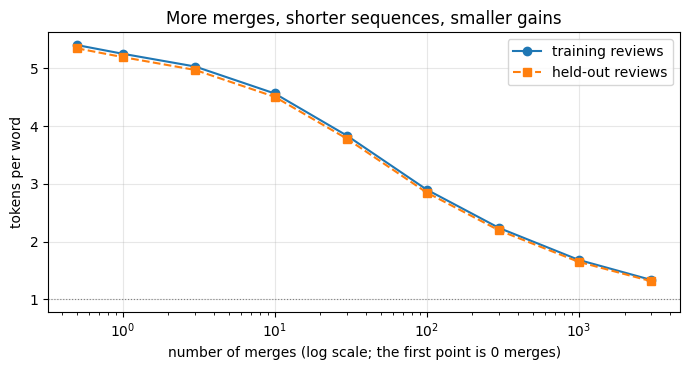

In [16]:
ks = [0] + CHECK
held_tpw = [bpe_stats(held_wf, k)[0] / n_held for k in ks]
for k, a, b in zip(ks, [train_tpw[k] for k in ks], held_tpw):
    print(f"merges {k:5d}   vocabulary {4 + n_base + k:5d}   tokens/word  train {a:.3f}   held-out {b:.3f}")

x = [max(k, 0.5) for k in ks]
plt.figure(figsize=(7, 3.8))
plt.plot(x, [train_tpw[k] for k in ks], "o-", label="training reviews")
plt.plot(x, held_tpw, "s--", label="held-out reviews")
plt.axhline(1.0, color="grey", lw=0.8, ls=":")
plt.xscale("log"); plt.xlabel("number of merges (log scale; the first point is 0 merges)")
plt.ylabel("tokens per word"); plt.title("More merges, shorter sequences, smaller gains")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Why we see this

The first hundred merges do most of the shortening; after that each tenfold increase in merges buys less.
The curve can approach one token per word but only by turning into a word vocabulary, with a merge for every
word in the corpus. The held-out curve sits a little above the training curve: the tokenizer fits the text
it was built on slightly better, as every fitted thing does.

---
## Step 17 - Digits get chopped wherever the counts say

The reviews contain years, scores and prices, so some digit strings were frequent enough to be merged.

> **Predict:** will `1000` and `1001` be split in the same places? Will `123456789` be split into equal chunks?

In [17]:
for n in ["10", "100", "101", "1000", "1001", "80", "85", "1995", "1996", "2001", "2010", "1234", "4321", "123456789"]:
    pieces = bpe_word(n)
    print(f"{n:>10s} -> {' | '.join(pieces)}")

        10 -> _10
       100 -> _100
       101 -> _10 | 1
      1000 -> _10 | 00
      1001 -> _100 | 1
        80 -> _8 | 0
        85 -> _8 | 5
      1995 -> _199 | 5
      1996 -> _199 | 6
      2001 -> _200 | 1
      2010 -> _20 | 1 | 0
      1234 -> _1 | 2 | 3 | 4
      4321 -> _4 | 3 | 2 | 1
 123456789 -> _1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9


### Why we see this

Frequent numbers (`10`, `100`) are single tokens; everything else is cut into whatever fragments happened to
be common in film reviews. `1000` is `_10` + `00` but `1001` is `_100` + `1`: two numbers that differ by one
are cut in different places, and the digits are not lined up by place value. A model doing arithmetic on such tokens
is adding numbers it cannot see column by column. The same blindness covers spelling: a model that receives
`_unbelievably` as one integer was never shown its letters.

---
## Step 18 - Nothing unknown: start from bytes

Our alphabet is the characters that happened to be in the reviews. Give the tokenizer anything else and it
has no symbol for it. **Byte-level BPE** fixes this: every text is stored as UTF-8 bytes, there are only 256
byte values, so a starting alphabet of 256 covers every language, emoji and typo there will ever be.

> **Predict:** how many bytes is `café`? And `नमस्ते` (six Unicode characters)? And one emoji?

In [18]:
for text in ["a naïve café", "el niño", "so cool 🙂"]:
    pieces = [vocab[i] for i in encode(text)]
    print(f"{text!r:22s} -> {pieces}   unknown tokens: {pieces.count('<unk>')}")
    print(f"{'':22s}    decodes to {decode_ids(encode(text))!r}")

print(f"\n{'text':<14s} {'characters':>10s} {'UTF-8 bytes':>12s}")
for text in ["hello", "café", "привет", "नमस्ते", "你好", "🙂"]:
    b = text.encode("utf-8")
    assert bytes(list(b)).decode("utf-8") == text             # bytes always round-trip
    print(f"{text:<14s} {len(text):10d} {len(b):12d}   {list(b)[:9]}{' ...' if len(b) > 9 else ''}")

print(f"\nGPT-2 (2019): 256 byte values + 50,000 merges + 1 end-of-text token = {256 + 50000 + 1:,}")
assert 256 + 50000 + 1 == 50257

'a naïve café'         -> ['_a', '_na', 'ï', 've', '_ca', 'f', 'é']   unknown tokens: 0
                          decodes to 'a naïve café'
'el niño'              -> ['_el', '_n', 'i', '<unk>', 'o']   unknown tokens: 1
                          decodes to 'el ni<unk>o'
'so cool 🙂'            -> ['_so', '_cool', '_', '<unk>']   unknown tokens: 1
                          decodes to 'so cool <unk>'

text           characters  UTF-8 bytes
hello                   5            5   [104, 101, 108, 108, 111]
café                    4            5   [99, 97, 102, 195, 169]
привет                  6           12   [208, 191, 209, 128, 208, 184, 208, 178, 208] ...
नमस्ते                  6           18   [224, 164, 168, 224, 164, 174, 224, 164, 184] ...
你好                      2            6   [228, 189, 160, 229, 165, 189]
🙂                       1            4   [240, 159, 153, 130]

GPT-2 (2019): 256 byte values + 50,000 merges + 1 end-of-text token = 50,257


### Why we see this

`é` and `ï` survive only because a few reviews happened to contain them. `ñ` and the emoji were never in the
training pile, so they become `<unk>`, and decoding cannot bring them back. With bytes as the starting alphabet
nothing is ever unknown. The table also shows who pays: before any
merge, an English letter is one byte, a Cyrillic letter two, a Devanagari or Chinese character three, an
emoji four. Merges learnt mostly from English text shorten English most, so the same sentence costs more
tokens in languages the training text held less of.

---
## Step 19 - Normalisation: what you decide before tokenizing

The same word can arrive as different sequences of code points. Tokenizers usually tidy text first, and every
tidying step is a decision about what the model will never see.

> **Predict:** `é` typed as one character and `é` typed as `e` plus a combining accent look identical. Are
> the two strings equal in Python?

In [19]:
one = "café"            # é as one code point
two = "café"           # e followed by a combining acute accent
print(f"{one!r} == {two!r}: {one == two}   lengths {len(one)} and {len(two)}, bytes {len(one.encode())} and {len(two.encode())}")
nfc = unicodedata.normalize("NFC", two)
print(f"after NFC normalisation equal: {nfc == one}")

def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if not unicodedata.combining(c))

for s in ["Café RÉSUMÉ", "US and us", "Polish and polish", "ﬁne"]:
    print(f"{s!r:22s} lower: {s.lower()!r:22s} no accents: {strip_accents(s.lower())!r:20s} NFKC: {unicodedata.normalize('NFKC', s)!r}")

'café' == 'café': False   lengths 4 and 5, bytes 5 and 6
after NFC normalisation equal: True
'Café RÉSUMÉ'          lower: 'café résumé'          no accents: 'cafe resume'        NFKC: 'Café RÉSUMÉ'
'US and us'            lower: 'us and us'            no accents: 'us and us'          NFKC: 'US and us'
'Polish and polish'    lower: 'polish and polish'    no accents: 'polish and polish'  NFKC: 'Polish and polish'
'ﬁne'                  lower: 'ﬁne'                  no accents: 'ﬁne'                NFKC: 'fine'


### Why we see this

Without normalisation, two strings that print identically become different tokens. With it, you pay in
information: lower-casing merges `US` with `us` and `Polish` with `polish`; stripping accents turns `résumé`
into `resume`. BERT's "uncased" models (2018) lower-case and strip accents; its "cased" models do not. Whatever
you choose must be applied identically when the model is trained and when it is used.

---
## Step 20 - Special tokens, padding and truncation

A model's input is rarely only the text. Markers are added for start and end, and a batch must be a rectangle,
so short rows are padded. All of these count towards the length.

> **Predict:** the first text below has 4 words. With `<bos>` and `<eos>` added, how long is its row? After
> truncating the second row to 12, is its `<eos>` still there? What does the review now seem to say?

In [20]:
batch = ["a truly wonderful film",
         "the first hour is slow and the acting is wooden but the ending is superb"]
rows = [[BOS] + encode(t) + [EOS] for t in batch]
T = max(len(r) for r in rows)
padded = np.array([r + [PAD] * (T - len(r)) for r in rows])            # pad on the right
mask = (padded != PAD).astype(int)
print("lengths with <bos> and <eos>:", [len(r) for r in rows], " -> batch shape", padded.shape)
for r, m in zip(padded, mask):
    print(" ".join(vocab[i] for i in r))
    print("mask:", m.tolist())

MAX_LEN = 12
cut = rows[1][:MAX_LEN]
print(f"\ntruncated to {MAX_LEN}: {' '.join(vocab[i] for i in cut)}")
print("the <eos> survived:", EOS in cut, "| words lost:", decode_ids(rows[1][MAX_LEN:-1]))

lengths with <bos> and <eos>: [6, 18]  -> batch shape (2, 18)
<bos> _a _truly _wonderful _film <eos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>
mask: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
<bos> _the _first _hour _is _slow _and _the _acting _is _wood en _but _the _ending _is _superb <eos>
mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

truncated to 12: <bos> _the _first _hour _is _slow _and _the _acting _is _wood en
the <eos> survived: False | words lost: but the ending is superb


### Why we see this

The four-word text needs six positions, not four: forget the special tokens and your length budget is wrong
by a few tokens on every row. Padding is harmless only if the mask tells the model (and the loss) to ignore
it. Truncation is silent: no error, the end of the text is gone, and with it the `<eos>` and here the
half of the review that carried the verdict. Padding went on the right, which suits training. A decoder that *generates* must
have its real text end at the right-hand edge, so batches for generation are padded on the left (Chapter 36).

---
## Step 21 - The bill for a bigger vocabulary: V × d, and rare tokens

Every token owns one row of the embedding table (Chapter 18), so the table has V × d numbers. And every
token must be seen often enough to learn its row.

> **Predict:** at width d = 768, how many parameters does the token table of a 50,257-token vocabulary have?
> And of a one-million-token vocabulary?

In [21]:
d = 768
print(f"{'vocabulary V':>14s} {'V x d  (d = 768)':>18s}")
for name, V in [("this lab", len(vocab)), ("BERT-base", 30522), ("GPT-2", 50257), ("", 100_000), ("", 1_000_000)]:
    print(f"{V:14,d} {V * d:18,d}   {name}")
assert 50257 * 768 == 38_597_376
print(f"\nGPT-2 small has 124,439,808 parameters; its token table is {100 * 38_597_376 / 124_439_808:.1f}% of them")

usage = Counter()
for w, c in train_wf.items():
    for s in bpe_word(w):
        usage[s] += c
counts = np.array([usage.get(t, 0) for t in vocab[4:]])
total = counts.sum()
print(f"\nour {len(counts):,} tokens over {total:,} training tokens:")
for lo in [1000, 100, 50]:
    print(f"  tokens used fewer than {lo:4d} times: {np.sum(counts < lo):5,d} = {100 * np.mean(counts < lo):.1f}% of the vocabulary")
top = np.sort(counts)[::-1]
print(f"  the 100 most used tokens cover {100 * top[:100].sum() / total:.1f}% of the text")
print(f"  the least used half of the vocabulary covers {100 * top[len(top) // 2:].sum() / total:.1f}% of the text")

  vocabulary V   V x d  (d = 768)
         3,069          2,356,992   this lab
        30,522         23,440,896   BERT-base
        50,257         38,597,376   GPT-2
       100,000         76,800,000   
     1,000,000        768,000,000   

GPT-2 small has 124,439,808 parameters; its token table is 31.0% of them



our 3,065 tokens over 642,275 training tokens:
  tokens used fewer than 1000 times: 2,968 = 96.8% of the vocabulary
  tokens used fewer than  100 times: 1,960 = 63.9% of the vocabulary
  tokens used fewer than   50 times:   900 = 29.4% of the vocabulary
  the 100 most used tokens cover 43.6% of the text
  the least used half of the vocabulary covers 10.2% of the text


### Why we see this

The table grows in a straight line with V: a million-token vocabulary at width 768 would need 768 million
parameters for the table alone, more than six times the whole of GPT-2 small. And the rows would be mostly
wasted: even in our 3,000-token vocabulary the hundred commonest tokens cover 44% of the text, and the rarer
half of the vocabulary covers about 10% of it. A row that is seldom used is seldom updated, so its vector stays
close to its random start. This is why text vocabularies settle between about 30,000 and 100,000 and not at a million.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 5: add `"sings " * 6` to the toy corpus | Which merge now enters the first nine? Does `_walk` still appear? | |
| 2 | Step 8: ask for 25 merges instead of 9 on the toy corpus | At which merge does the loop run out of pairs? What has the tokenizer turned into by then? | |
| 3 | Step 6: change the tie rule in `best_pair` to prefer the alphabetically *last* pair | Which toy merge changes first? Do the final pieces of `walking` change? | |
| 4 | Step 11: `N_MERGES = 300` (and remove 1000 and 3000 from `CHECK`) | Tokens per word on held-out text? How many pieces for `unwatchableness`? | |
| 5 | Step 2: build from 200 reviews instead of 2,000 | Does the gap between training and held-out tokens per word grow or shrink? | |
| 6 | Step 9: encode `walkingtalking` and `kingwalk` with the toy merges | Which pieces appear? Where can `_walk` and `_talk` not be used, and why? | |
| 7 | Step 13: remove `.lower()` from `encode` and encode `"The Plot"` | How many unknown tokens? | |
| 8 | Step 20: pad on the left instead of the right | Where does the mask have its zeros? Which position holds the last real token? | |

---
## Exercises

1. **Byte-level BPE.** Change `as_symbols` so that a word becomes its UTF-8 bytes (one symbol per byte, written
   as two hex digits), start from all 256 byte values, and train on the reviews plus a few sentences in another
   script that you type in. Check that nothing is ever unknown, and count tokens per word for each language.
2. **WordPiece-style scoring.** Instead of the most frequent pair, merge the pair with the highest
   `count(ab) / (count(a) × count(b))`. Train 300 merges on the toy corpus and on the reviews. Which early merges
   differ, and why does this score like rare symbols that always appear together?
3. **Greedy longest-match encoding.** Write an encoder that ignores merge order and, at each position, takes
   the longest vocabulary entry that fits. Find a word on which it disagrees with `bpe_word`.
4. **Count the letter r.** Using only token ids (no access to `vocab`), can you write a function that counts
   how many times the letter `r` occurs in a text? What extra table would you need, and what does that tell
   you about what a language model has to learn to do the same?
5. **A fair loss comparison.** Two models report an average loss per token of 3.0, one with a tokenizer that
   gives 1.3 tokens per word and one that gives 5.6. Convert both to a loss per word. Which model is better?
6. **Leak check.** Rebuild the word vocabulary from training *and* held-out reviews together and repeat
   Step 15. How much does the unknown rate flatter itself?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Characters | tiny vocabulary, no unknowns for seen characters, 5 to 6 tokens per English word |
| Words | 1 token per word, vocabulary of tens of thousands and never complete, unknown words, no sharing between `walk` and `walking` |
| BPE training | count adjacent pairs; merge the commonest; repeat; the ordered merge list is the tokenizer |
| Toy corpus | 28 words, 12 symbols, 171 tokens; 9 merges give 21 symbols, 54 tokens |
| BPE encoding | replay the merges in order (or: repeatedly apply the lowest-rank merge present) |
| Vocabulary size | specials + starting symbols + number of merges |
| The `_` marker | the space rides at the front of the next word, so `_cat` and `cat` are different tokens |
| Unknowns | only for a character outside the starting alphabet; byte-level BPE (256 bytes) has none |
| GPT-2 (2019) | 256 bytes + 50,000 merges + 1 end-of-text = 50,257 |
| Round trip | exact only if nothing was normalised away (case, accents, repeated spaces) |
| Length | count the special tokens; padding needs a mask; truncation is silent |
| Embedding bill | V × d: 50,257 × 768 = 38,597,376 |
| Build and test | build the vocabulary on training text only; ship the tokenizer with the model |